## Code for plotting results from parameter recovery

In [1]:
import dill
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr
import jax.numpy as jnp
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path

num_trials = 136 # 500, 1000, 2500, 5000
num_iters = 1500 # number of iterations for Gibbs sampler
burn_in = 500 # number of trials thrown away (make sure this is the same as in simulation script)
num_datasets = 50
num_subjects = 344
num_inputs = 3


true_mu_a = 0.98
true_sigma_a = 0.03
true_mu_w = jnp.array([0.0, 0.2, -0.1])
true_sigma_w = jnp.array([1.0, 1.0, 1.0])
true_mu_sigmasq = 0.2
true_beta_sigmasq = 0.5
true_sigma_mu_x = 0.5




In [2]:
sns.set_theme(style="ticks", context="paper",
              font="Arial",
              rc={"font.size": 20,
                "axes.titlesize": 20,
                "axes.labelsize": 20,
                "lines.linewidth": 1.5,
                "xtick.labelsize": 15,
                "ytick.labelsize": 15,
                "xtick.major.size": 5,
                "ytick.major.size": 5,
                "xtick.minor.size": 2,
                "ytick.minor.size": 2,
                "axes.spines.right": False,
                "axes.spines.top": False
        })

In [3]:
from pathlib import Path
import os

data_dir = Path(
    "/Users/daviddejonghe/Documents/Psychologie/Masterproef/"
    "simulationsHmfc/demo/Study1_Benwell/Param_recovery"
)

file_path = data_dir / "344subjects_136trials.dil"

with file_path.open("rb") as file:
    variable_names = dill.load(file)
    for name in variable_names:
        globals()[name] = dill.load(file)

num_datasets = len(all_true_params)

assert all_true_states[0].shape == (num_subjects, num_trials)
assert all_posterior_samples_a[0].shape[0] == num_iters

plot_dir = data_dir / "figuren_136trials"
plot_dir.mkdir(exist_ok=True)
os.chdir(plot_dir)

print(f"loaded: {num_datasets} datasets")
print(f"Figures will be saved in: {plot_dir}")

loaded: 50 datasets
Figures will be saved in: /Users/daviddejonghe/Documents/Psychologie/Masterproef/simulationsHmfc/demo/Study1_Benwell/Param_recovery/figuren_136trials


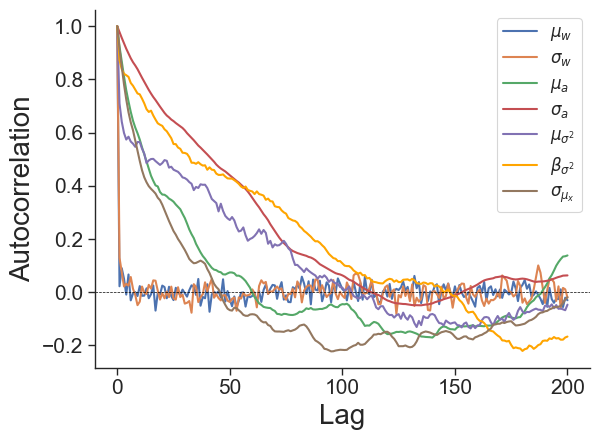

In [4]:
n_lag = 200
dataset = 7

acf_mu_w = sm.tsa.acf(all_posterior_samples_mu_w[dataset][burn_in:, 0], nlags=n_lag)
acf_sigma_w = sm.tsa.acf(all_posterior_samples_sigma_w[dataset][burn_in:, 0], nlags=n_lag)
acf_mu_a = sm.tsa.acf(all_posterior_samples_mu_a[dataset][burn_in:], nlags=n_lag)
acf_sigma_a = sm.tsa.acf(all_posterior_samples_sigma_a[dataset][burn_in:], nlags=n_lag)
acf_mu_sigmasq = sm.tsa.acf(all_posterior_samples_mu_sigmasq[dataset][burn_in:], nlags=n_lag)
acf_beta_sigmasq = sm.tsa.acf(all_posterior_samples_beta_sigmasq[dataset][burn_in:], nlags=n_lag)
acf_sigma_mu_x = sm.tsa.acf(all_posterior_samples_sigma_mu_x[dataset][burn_in:], nlags=n_lag)


plt.plot(acf_mu_w, label=r"$\mu_w$")
plt.plot(acf_sigma_w, label=r"$\sigma_w$")
plt.plot(acf_mu_a, label=r"$\mu_a$")
plt.plot(acf_sigma_a, label=r"$\sigma_a$")
plt.plot(acf_mu_sigmasq, label=r"$\mu_{\sigma^2}$")
plt.plot(acf_beta_sigmasq, label=r"$\beta_{\sigma^2}$", color='orange')
plt.plot(acf_sigma_mu_x, label=r"$\sigma_{\mu_x}$")
plt.axhline(0, color='black', linestyle='--', linewidth=0.5)
plt.legend(fontsize=12)
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.tight_layout()
plt.savefig("acf_group_params.png", transparent=True, bbox_inches='tight', dpi=600)

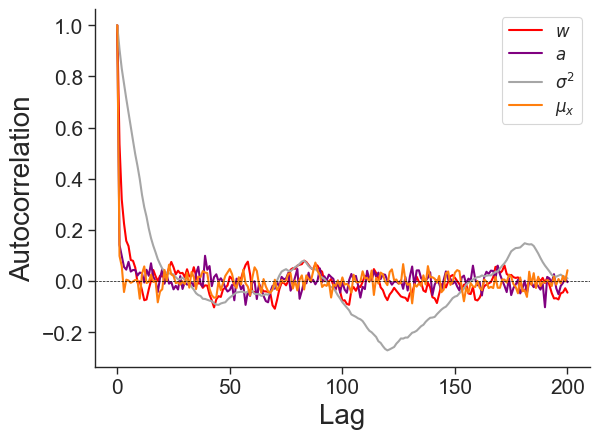

In [5]:
n_lag = 200
dataset = 7
subject_id = 7

acf_w = sm.tsa.acf(all_posterior_samples_w[dataset][burn_in:, subject_id, 0], nlags=n_lag)
acf_a = sm.tsa.acf(all_posterior_samples_a[dataset][burn_in:, subject_id], nlags=n_lag)
acf_sigmasq = sm.tsa.acf(all_posterior_samples_sigmasq[dataset][burn_in:, subject_id], nlags=n_lag)
acf_mu_x = sm.tsa.acf(all_posterior_samples_mu_x[dataset][burn_in:, subject_id], nlags=n_lag)

plt.plot(acf_w, label=r"$w$", color='red')
plt.plot(acf_a, label=r"$a$", color='purple')
plt.plot(acf_sigmasq, label=r"$\sigma^2$", color='#A6A6A6')
plt.plot(acf_mu_x, label=r"$\mu_x$", color='#FF7F0E')
plt.axhline(0, color='black', linestyle='--', linewidth=0.5)
plt.legend(fontsize=12)
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.savefig("acf_per_subject_params.png", transparent=True, bbox_inches='tight', dpi=600)

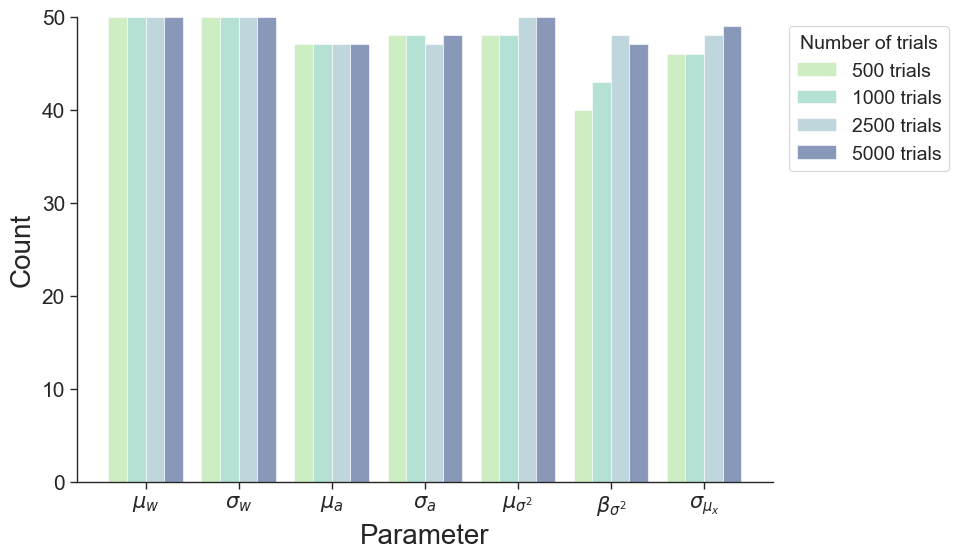

In [6]:
conditions = [r'$\mu_w$', '$\sigma_w$', '$\mu_a$', '$\sigma_a$', '$\mu_{\sigma^2}$', r'$\beta_{\sigma^2}$', r'$\sigma_{\mu_x}$']
trials = [500, 1000, 2500, 5000]
counts = [
    [50, 50, 50, 50],
    [50, 50, 50, 50],
    [47, 47, 47, 47], 
    [48, 48, 47, 48],
    [48, 48, 50, 50],
    [40, 43, 48, 47],
    [46, 46, 48, 49],
]

counts = np.array(counts) 

x = np.arange(len(conditions))  # base x locations for each condition
bar_width = 0.2

fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#ADE19C','#81CDB6','#94BBC6','#3b528b']

for i in range(len(trials)):
    ax.bar(x + i * bar_width, counts[:, i], width=bar_width, 
           label=f'{trials[i]} trials', color=colors[i], alpha=0.6)
    
ax.set_ylabel('Count')
ax.set_xlabel('Parameter')
ax.set_xticks(x + bar_width * 1.5)  # center the ticks
ax.set_xticklabels(conditions)
ax.set_ylim(0, 50)
ax.legend(title='Number of trials',bbox_to_anchor=(1.01, 1), loc='upper left', title_fontsize=14, fontsize=14)
plt.tight_layout()
plt.savefig("counts_95CI_trials.png", transparent=True, bbox_inches='tight', dpi=600)


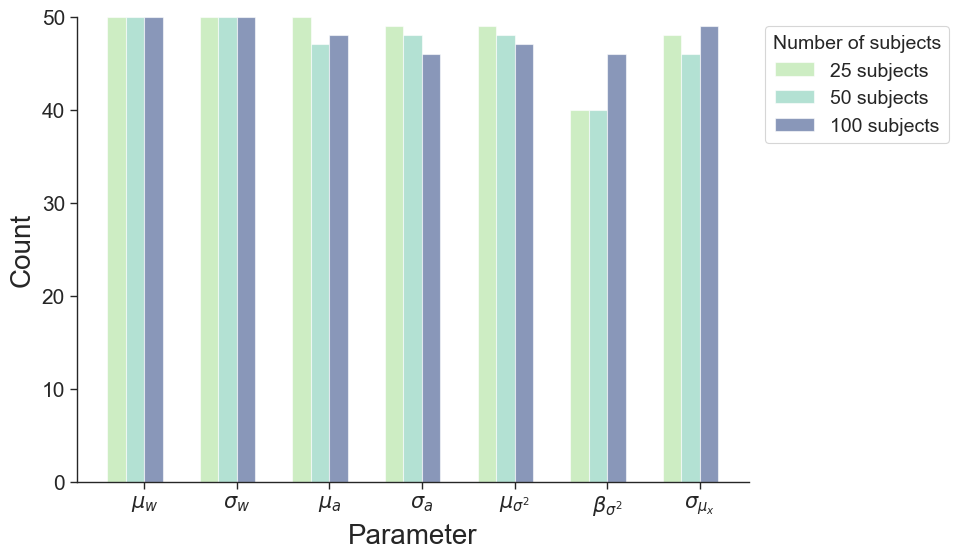

In [7]:
conditions = [r'$\mu_w$', '$\sigma_w$', '$\mu_a$', '$\sigma_a$', '$\mu_{\sigma^2}$', r'$\beta_{\sigma^2}$', r'$\sigma_{\mu_x}$']
subjects = [25, 50, 100]
counts = [
    [50, 50, 50],
    [50, 50, 50],
    [50, 47, 48], 
    [49, 48, 46],
    [49, 48, 47],
    [40, 40, 46],
    [48, 46, 49],
]

counts = np.array(counts) 

x = np.arange(len(conditions))  # base x locations for each condition
bar_width = 0.2

fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#ADE19C','#81CDB6','#3b528b']

for i in range(len(subjects)):
    ax.bar(x + i * bar_width, counts[:, i], width=bar_width, 
           label=f'{subjects[i]} subjects', color=colors[i], alpha=0.6)
    
ax.set_ylabel('Count')
ax.set_xlabel('Parameter')
ax.set_xticks(x + bar_width * 1.5)  # center the ticks
ax.set_xticklabels(conditions)
ax.set_ylim(0, 50)
ax.legend(title='Number of subjects',bbox_to_anchor=(1.01, 1), loc='upper left', title_fontsize=14, fontsize=14)
plt.tight_layout()
plt.savefig("counts_95CI_subjects.png", transparent=True, bbox_inches='tight', dpi=600)

In [8]:
"""
Check log joint probability to assess convergence and determine number of burn-in iterations
"""

with PdfPages(f'{num_subjects}subjects_{num_trials}trials_log_joint_prob.pdf') as pdf:
  for dataset in range(num_datasets):
      
      plt.figure(figsize=(8, 6), dpi=600)
      plt.plot(jnp.stack(all_lps[dataset])/(num_trials*num_subjects)) # normalized log joint prob
      plt.title(r"Dataset {:d}".format(dataset))
      plt.xlabel("Iteration")
      plt.ylabel("Log joint probability")

      pdf.savefig()
      plt.close()

In [9]:
"""
Estimated criterion fluctuations for one example dataset
"""

# Select a dataset
dataset = 0

with PdfPages(f'{num_subjects}subjects_{num_trials}trials_estimated_states_one_dataset.pdf') as pdf:
  for subject in range(num_subjects):
      
      plt.figure(figsize=(8, 6), dpi=600)
      plt.plot(all_true_states[dataset][subject], label="True states", linewidth=2, color='red', alpha=.6)
      plt.plot(all_posterior_samples_states[dataset][subject], label="Inferred states", linewidth=2.5)
      plt.fill_between(jnp.arange(num_trials),
                all_posterior_samples_states[dataset][subject] - 2 * all_posterior_samples_states_sd[dataset][subject],
                all_posterior_samples_states[dataset][subject] + 2 * all_posterior_samples_states_sd[dataset][subject], color='r', alpha=0.25)
      plt.xlabel("Trial")
      plt.ylabel("Criterion $x_t$")
      plt.title(r"Subject {:d}".format(subject))
      plt.legend(loc='lower right')
      r, p = spearmanr(all_true_states[dataset][subject], all_posterior_samples_states[dataset][subject])
      plt.annotate('r = {:.2f}'.format(r), xy=(0.05, 0.90), xycoords='axes fraction')

      pdf.savefig()
      plt.close()

Text(0.05, 0.92, 'r = 0.93')

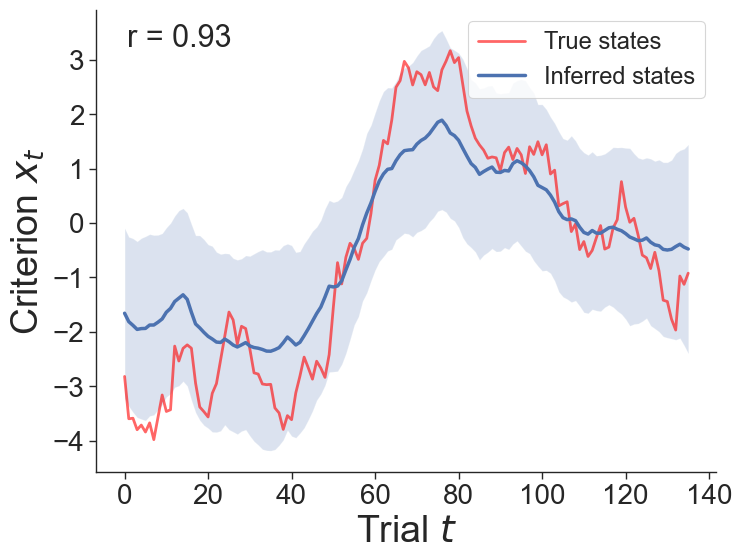

In [10]:
"""
Estimated criterion fluctuations for one example participant
"""

dataset = 0
subject = 2

plt.figure(figsize=(8, 6))
plt.plot(all_true_states[dataset][subject], label="True states", linewidth=2, color='red', alpha=.6)
plt.plot(all_posterior_samples_states[dataset][subject], label="Inferred states", linewidth=2.5)
plt.fill_between(jnp.arange(num_trials),
          all_posterior_samples_states[dataset][subject] - 2 * all_posterior_samples_states_sd[dataset][subject],
          all_posterior_samples_states[dataset][subject] + 2 * all_posterior_samples_states_sd[dataset][subject], alpha=0.2)
plt.xlabel("Trial $t$", fontsize=27)
plt.ylabel("Criterion $x_t$", fontsize=27)
plt.xticks(size=20)
plt.yticks(size=20)
#plt.ylim(-5.5,5.5)
#plt.title(r"Subject {:d}".format(subject))
plt.legend(loc='upper right', fontsize=17)
r, p = spearmanr(all_true_states[dataset][subject], all_posterior_samples_states[dataset][subject])
plt.annotate('r = {:.2f}'.format(r), xy=(0.05, 0.92), xycoords='axes fraction', fontsize=22)

#plt.savefig("estimated_criterion.png", transparent=True, dpi=600)

In [11]:
"""
Recovery criterion fluctuations all datasets
"""

average_recovery_states_all_datasets = []
median_recovery_states_all_datasets = []

with PdfPages(f'{num_subjects}subjects_{num_trials}trials_recovery_states.pdf') as pdf:
  for dataset in range(num_datasets):

    correlations_inferred_and_fitted_states = []
    
    for subject in range(num_subjects):
        r, _= spearmanr(all_true_states[dataset][subject], all_posterior_samples_states[dataset][subject])
        correlations_inferred_and_fitted_states.append(r)
    
    correlations_inferred_and_fitted_states = jnp.array(correlations_inferred_and_fitted_states)
    
    mean_value = jnp.mean(correlations_inferred_and_fitted_states)
    median_value = jnp.median(correlations_inferred_and_fitted_states)
    
    average_recovery_states_all_datasets.append(mean_value)
    median_recovery_states_all_datasets.append(median_value)
    
    plt.figure(figsize=(8, 6), dpi=600)
    sns.histplot(data=correlations_inferred_and_fitted_states, bins=25)
    plt.annotate(f'Mean: {mean_value:.2f}', xy=(0.05, 0.90), xycoords='axes fraction', fontsize=18)
    plt.annotate(f'Median: {median_value:.2f}', xy=(0.05, 0.85), xycoords='axes fraction', fontsize=18)
    plt.xlabel('Spearman correlation generative and fitted criterion', fontsize=18)
    plt.ylabel('Count', fontsize=18)
    plt.title(r"Dataset {:d}".format(dataset))
    plt.xlim(0,1)
    
    pdf.savefig()
    plt.close()

(0.0, 1.0)

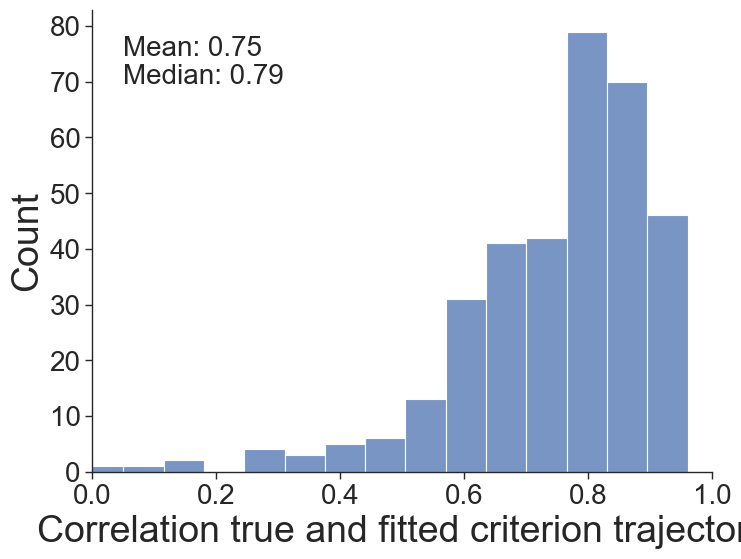

In [12]:
"""
Recovery criterion fluctuations one example dataset
"""

dataset = 14


correlations_inferred_and_fitted_states = []

for subject in range(num_subjects):
    r, _= spearmanr(all_true_states[dataset][subject], all_posterior_samples_states[dataset][subject])
    correlations_inferred_and_fitted_states.append(r)

correlations_inferred_and_fitted_states = jnp.array(correlations_inferred_and_fitted_states)

mean_value = jnp.mean(correlations_inferred_and_fitted_states)
median_value = jnp.median(correlations_inferred_and_fitted_states)

average_recovery_states_all_datasets.append(mean_value)
median_recovery_states_all_datasets.append(median_value)

plt.figure(figsize=(8, 6))
sns.histplot(data=correlations_inferred_and_fitted_states, bins=15)

#plt.title("Correlation between inferred and fitted states over subjects")
plt.annotate(f'Mean: {mean_value:.2f}', xy=(0.05, 0.90), xycoords='axes fraction', fontsize=20)
plt.annotate(f'Median: {median_value:.2f}', xy=(0.05, 0.84), xycoords='axes fraction', fontsize=20)
plt.xticks(size=20)
plt.yticks(size=20)
plt.xlabel('Correlation true and fitted criterion trajectory', fontsize=27)
plt.ylabel('Count', fontsize=27)
#plt.title(r"Dataset {:d}".format(dataset))
plt.xlim(0,1)
#plt.savefig("recovery_criterion.png", transparent=True, dpi=600)

In [13]:
"""
Compare true and inferred estimates of a_i averaged over iterations (minus the burn-in) for all datasets
"""


with PdfPages(f'{num_subjects}subjects_{num_trials}trials_recovery_a.pdf') as pdf:
  for dataset in range(num_datasets):
    
    a_min = min(all_true_params[dataset]['a'].min(), jnp.mean(all_posterior_samples_a[dataset][burn_in:], axis=0).min())
    a_max = max(all_true_params[dataset]['a'].max(), jnp.mean(all_posterior_samples_a[dataset][burn_in:], axis=0).max())
    
    plt.figure(figsize=(8, 6), dpi=600)
    plt.scatter(all_true_params[dataset]['a'], jnp.mean(all_posterior_samples_a[dataset][burn_in:], axis=0))
    plt.plot([a_min, a_max], [a_min, a_max], '-k')
    plt.xlabel("True $a$")
    plt.ylabel("Inferred $a$")
    plt.title(r"Dataset {:d}".format(dataset))
    plt.gca().set_aspect(1.0)
    r, p = spearmanr(all_true_params[dataset]['a'], jnp.mean(all_posterior_samples_a[dataset][burn_in:], axis=0))
    plt.annotate('r = {:.2f}'.format(r), xy=(0.05, 0.85), xycoords='axes fraction')
        
    pdf.savefig()
    plt.close()

Text(0.05, 0.85, 'r = 0.46')

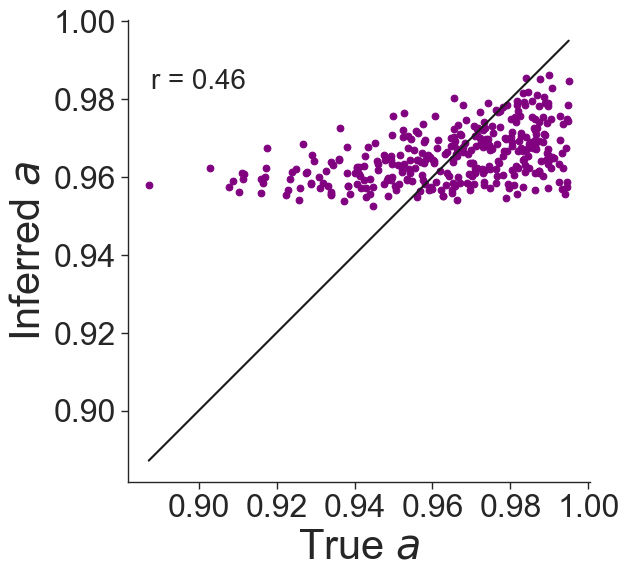

In [14]:
"""
Compare true and inferred estimates of a_i averaged over iterations (minus the burn-in) for one example dataset
"""

dataset = 12

a_min = min(all_true_params[dataset]['a'].min(), jnp.mean(all_posterior_samples_a[dataset][burn_in:], axis=0).min())
a_max = max(all_true_params[dataset]['a'].max(), jnp.mean(all_posterior_samples_a[dataset][burn_in:], axis=0).max())

plt.figure(figsize=(8, 6))
plt.scatter(all_true_params[dataset]['a'], jnp.mean(all_posterior_samples_a[dataset][burn_in:], axis=0), color="purple")
plt.plot([a_min, a_max], [a_min, a_max], '-k')
plt.xlabel("True $a$", size=30)
plt.ylabel("Inferred $a$",size=30)
plt.xticks(size=23)
plt.yticks(size=23)

#plt.title(r"Dataset {:d}".format(dataset))
plt.gca().set_aspect(1.0)
r, p = spearmanr(all_true_params[dataset]['a'], jnp.mean(all_posterior_samples_a[dataset][burn_in:], axis=0))
plt.annotate('r = {:.2f}'.format(r), xy=(0.05, 0.85), xycoords='axes fraction')
#plt.savefig("recovery_a_5000.png", transparent=True, dpi=600)


In [15]:
"""
Compare true and inferred estimates of sigma_sq averaged over iterations (minus the burn-in) for all datasets
"""

with PdfPages(f'{num_subjects}subjects_{num_trials}trials_recovery_sigmasq.pdf') as pdf:
  for dataset in range(num_datasets):
    
    sigmasq_min = min(all_true_params[dataset]['sigmasq'].min(), jnp.mean(all_posterior_samples_sigmasq[dataset][burn_in:], axis=0).min())
    sigmasq_max = max(all_true_params[dataset]['sigmasq'].max(), jnp.mean(all_posterior_samples_sigmasq[dataset][burn_in:], axis=0).max())
    
    plt.figure(figsize=(8, 6), dpi=600)
    plt.scatter(all_true_params[dataset]['sigmasq'], jnp.mean(all_posterior_samples_sigmasq[dataset][burn_in:], axis=0))
    plt.plot([sigmasq_min, sigmasq_max], [sigmasq_min, sigmasq_max], '-k')
    plt.xlabel("True $\sigma^2$")
    plt.ylabel("Inferred $\sigma^2$")
    plt.title(r"Dataset {:d}".format(dataset))
    plt.gca().set_aspect(1.0)
    r, p = spearmanr(all_true_params[dataset]['sigmasq'], jnp.mean(all_posterior_samples_sigmasq[dataset][burn_in:], axis=0))
    plt.annotate('r = {:.2f}'.format(r), xy=(0.05, 0.85), xycoords='axes fraction')
        
    pdf.savefig()
    plt.close()

Text(0.05, 0.85, 'r = 0.51')

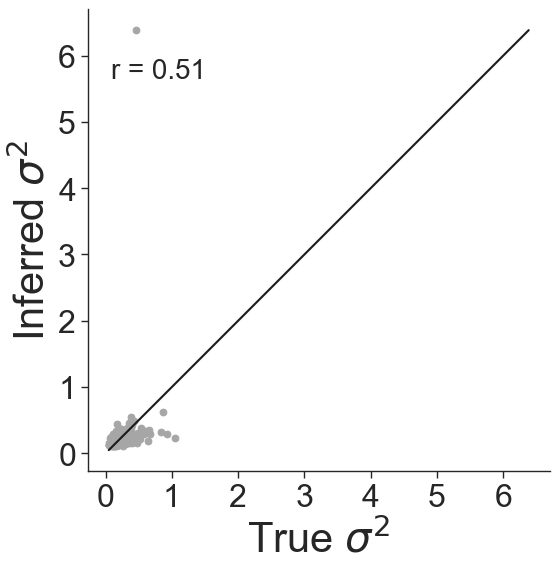

In [16]:
"""
Compare true and inferred estimates of sigma_sq averaged over iterations (minus the burn-in) for one example dataset
"""

dataset = 8

sigmasq_min = min(all_true_params[dataset]['sigmasq'].min(), jnp.mean(all_posterior_samples_sigmasq[dataset][burn_in:], axis=0).min())
sigmasq_max = max(all_true_params[dataset]['sigmasq'].max(), jnp.mean(all_posterior_samples_sigmasq[dataset][burn_in:], axis=0).max())

plt.figure(figsize=(8, 6))
plt.scatter(all_true_params[dataset]['sigmasq'], jnp.mean(all_posterior_samples_sigmasq[dataset][burn_in:], axis=0), color="#A6A6A6")
plt.plot([sigmasq_min, sigmasq_max], [sigmasq_min, sigmasq_max], '-k')
plt.xticks(size=23)
plt.yticks(size=23)
plt.xlabel("True $\sigma^2$", size=30)
plt.ylabel("Inferred $\sigma^2$",size=30)
#plt.title(r"Dataset {:d}".format(dataset))
plt.gca().set_aspect(1.0)
r, p = spearmanr(all_true_params[dataset]['sigmasq'], jnp.mean(all_posterior_samples_sigmasq[dataset][burn_in:], axis=0))
plt.annotate('r = {:.2f}'.format(r), xy=(0.05, 0.85), xycoords='axes fraction')
#plt.savefig("recovery_sigmasq_5000.png", transparent=True, dpi=600)


In [17]:
"""
Compare true and inferred estimates of mu_x averaged over iterations (minus the burn-in) for all datasets
"""

with PdfPages(f'{num_subjects}subjects_{num_trials}trials_recovery_mu_x.pdf') as pdf:
  for dataset in range(num_datasets):
    
    mu_x_min = min(all_true_params[dataset]['mu_x'].min(), jnp.mean(all_posterior_samples_mu_x[dataset][burn_in:], axis=0).min())
    mu_x_max = max(all_true_params[dataset]['mu_x'].max(), jnp.mean(all_posterior_samples_mu_x[dataset][burn_in:], axis=0).max())
    
    plt.figure(figsize=(8, 6), dpi=600)
    plt.scatter(all_true_params[dataset]['mu_x'], jnp.mean(all_posterior_samples_mu_x[dataset][burn_in:], axis=0))
    plt.plot([mu_x_min, mu_x_max], [mu_x_min, mu_x_max], '-k')
    plt.xlabel("True $\mu_0$")
    plt.ylabel("Inferred $\mu_0$")
    plt.title(r"Dataset {:d}".format(dataset))
    plt.gca().set_aspect(1.0)
    r, p = spearmanr(all_true_params[dataset]['mu_x'], jnp.mean(all_posterior_samples_mu_x[dataset][burn_in:], axis=0))
    plt.annotate('r = {:.2f}'.format(r), xy=(0.05, 0.85), xycoords='axes fraction')
        
    pdf.savefig()
    plt.close()

Text(0.05, 0.85, 'r = 0.51')

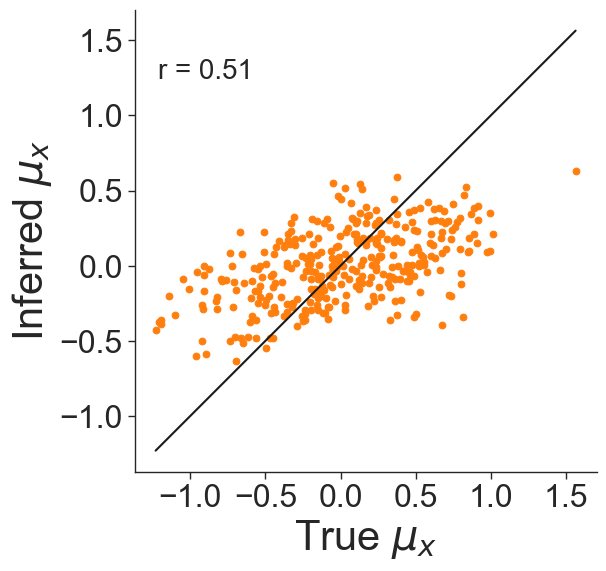

In [18]:
"""
Compare true and inferred estimates of mu_x averaged over iterations (minus the burn-in) for one example dataset
"""

dataset = 29

mu_x_min = min(all_true_params[dataset]['mu_x'].min(), jnp.mean(all_posterior_samples_mu_x[dataset][burn_in:], axis=0).min())
mu_x_max = max(all_true_params[dataset]['mu_x'].max(), jnp.mean(all_posterior_samples_mu_x[dataset][burn_in:], axis=0).max())

plt.figure(figsize=(8, 6))
plt.scatter(all_true_params[dataset]['mu_x'], jnp.mean(all_posterior_samples_mu_x[dataset][burn_in:], axis=0), color="#FF7F0E")
plt.plot([mu_x_min, mu_x_max], [mu_x_min, mu_x_max], '-k')
plt.xticks(size=23)
plt.yticks(size=23)
plt.xlabel("True $\mu_x$", size=30)
plt.ylabel("Inferred $\mu_x$",size=30)
#plt.title(r"Dataset {:d}".format(dataset))
plt.gca().set_aspect(1.0)
r, p = spearmanr(all_true_params[dataset]['mu_x'], jnp.mean(all_posterior_samples_mu_x[dataset][burn_in:], axis=0))
plt.annotate('r = {:.2f}'.format(r), xy=(0.05, 0.85), xycoords='axes fraction')
#plt.savefig("recovery_mu_x_5000.png", transparent=True, dpi=600)

In [19]:
"""
Compare true and inferred estimates of w averaged over iterations (minus the burn-in) for all datasets
"""

with PdfPages(f'{num_subjects}subjects_{num_trials}trials_recovery_w.pdf') as pdf:
  for dataset in range(num_datasets):
      
    w_min = min(all_true_params[dataset]["w"].min(), jnp.mean(all_posterior_samples_w[dataset][burn_in:,:,:], axis=0).min())
    w_max = max(all_true_params[dataset]["w"].max(), jnp.mean(all_posterior_samples_w[dataset][burn_in:,:,:], axis=0).max())
    
    fig, axs = plt.subplots(1, num_inputs, sharey=True, figsize=(10, 5), dpi=600)
    fig.suptitle(r"Dataset {:d}".format(dataset), size=20)
    fig.subplots_adjust(top=1.3)
    for d, ax in enumerate(axs):
        ax.scatter(all_true_params[dataset]["w"][:, d], jnp.mean(all_posterior_samples_w[dataset][burn_in:,:,d], axis=0))
        ax.set_xlabel(r"True $w_{:d}$".format(d), size=20)
        ax.set_ylabel(r"Inferred $w_{:d}$".format(d), size=20)
        ax.plot([w_min, w_max], [w_min, w_max], '-k')
        ax.set_aspect(1.0)
        r, p = spearmanr(all_true_params[dataset]["w"][:, d], jnp.mean(all_posterior_samples_w[dataset][burn_in:,:,d], axis=0))
        ax.annotate('r = {:.2f}'.format(r), xy=(0.05, 0.85), xycoords='axes fraction', fontsize=18)
        
    pdf.savefig()
    plt.close()

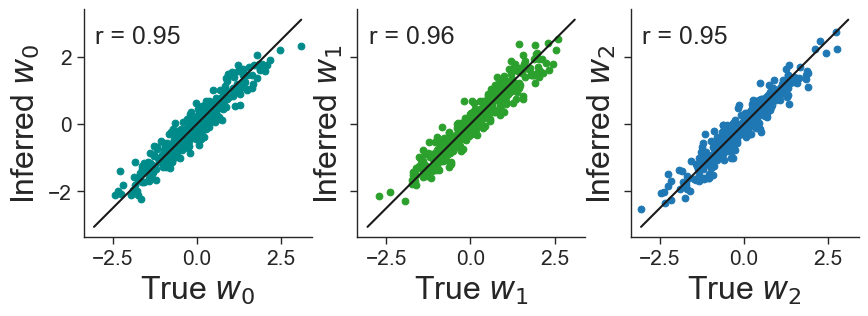

In [20]:
"""
Compare true and inferred estimates of w averaged over iterations (minus the burn-in) for one example dataset
"""

dataset = 0
colors = ['darkcyan', '#2ca02c', '#1f77b4', '#ff7f0e']
w_min = min(all_true_params[dataset]["w"].min(), jnp.mean(all_posterior_samples_w[dataset][burn_in:,:,:], axis=0).min())
w_max = max(all_true_params[dataset]["w"].max(), jnp.mean(all_posterior_samples_w[dataset][burn_in:,:,:], axis=0).max())

fig, axs = plt.subplots(1, num_inputs, sharey=True, figsize=(10, 5))
#fig.suptitle(r"Dataset {:d}".format(dataset))
fig.subplots_adjust(top=1.3)

for d, ax in enumerate(axs):
    ax.scatter(all_true_params[dataset]["w"][:, d], jnp.mean(all_posterior_samples_w[dataset][burn_in:,:,d], axis=0), color= colors[d])
    ax.set_xlabel(r"True $w_{:d}$".format(d), size=23)
    ax.set_ylabel(r"Inferred $w_{:d}$".format(d), size=23)
    ax.plot([w_min, w_max], [w_min, w_max], '-k')
    ax.set_aspect(1.0)
    r, p = spearmanr(all_true_params[dataset]["w"][:, d], jnp.mean(all_posterior_samples_w[dataset][burn_in:,:,d], axis=0))
    ax.annotate('r = {:.2f}'.format(r), xy=(0.05, 0.85), xycoords='axes fraction', fontsize=18)

plt.savefig("recovery_w_5000.png", transparent=True, dpi=600)

In [21]:
# ================================================================== #
# GLOBAL (HIERARCHICAL) PARAMETERS
# ================================================================== #

"""
Posterior distributions of mu_w (mean of normal distribution for w_i)
"""



with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_mu_w.pdf') as pdf:
    for dataset in range(num_datasets):
        fig, axs = plt.subplots(1, num_inputs, sharey=True, figsize=(10, 5), dpi=600)
        fig.suptitle("Posterior distributions", fontsize=16)
        fig.text(0.5, 0.93, "Dataset {:d}".format(dataset), ha='center', va='top', fontsize=12)
        
        mean_true_per_subject_w = jnp.mean(all_true_params[dataset]['w'], axis=0)
        for d, ax in enumerate(axs):
            ax.hist(all_posterior_samples_mu_w[dataset][burn_in:, d], bins=30)
            ax.axvline(x=true_mu_w[d], color='black', linewidth=3)
            ax.axvline(x=mean_true_per_subject_w[d], color='red', linewidth=3)
            
            if d == 0:
                ax.set_ylabel("Count", fontsize=15)
            ax.set_xlabel(r"$w_{:d}$".format(d), fontsize=15)
            
        fig.legend([r"True $w$", r'Mean true per-subject $w_i$'])
        
        pdf.savefig()
        plt.close()
        

In [22]:
# Same as above but now shown over time
with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_mu_w_over_iterations.pdf') as pdf:
    for dataset in range(num_datasets):
        fig, axs = plt.subplots(1, num_inputs, sharey=True, figsize=(10, 5), dpi=600)
        fig.suptitle("Posterior distributions", fontsize=16)
        fig.text(0.5, 0.93, "Dataset {:d}".format(dataset), ha='center', va='top', fontsize=12)
        
        mean_true_per_subject_w = jnp.mean(all_true_params[dataset]['w'], axis=0)
        for d, ax in enumerate(axs):
            ax.plot(all_posterior_samples_mu_w[dataset][burn_in:, d])
            ax.axhline(y=true_mu_w[d], color='black')
            ax.axhline(y=mean_true_per_subject_w[d], color='red')
            ax.set_xlabel("Iteration", fontsize=15)
            ax.set_ylabel(r"$w_{:d}$".format(d), fontsize=15)
            
        fig.legend([Line2D([0], [0], color='black'), Line2D([0], [0], color='red')],[r"True $w$", r'Mean true per-subject $w_i$']) # fix to have black line in legend (without it is blue)

        pdf.savefig()
        plt.close()

In [23]:
"""
Posterior distributions of sigma_w (variance of normal distribution for w_i)
"""

with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_sigma_w.pdf') as pdf:
    for dataset in range(num_datasets):
        fig, axs = plt.subplots(1, num_inputs, sharey=True, figsize=(10, 5), dpi=600)
        fig.suptitle("Posterior distributions", fontsize=16)
        fig.text(0.5, 0.93, "Dataset {:d}".format(dataset), ha='center', va='top', fontsize=12)
        
        sd_true_per_subject_w = jnp.std(all_true_params[dataset]['w'], axis=0)
        for d, ax in enumerate(axs):
            ax.hist(all_posterior_samples_sigma_w[dataset][burn_in:, d], bins=30)
            ax.axvline(x=true_sigma_w[d], color='black')
            ax.axvline(x=sd_true_per_subject_w[d], color='red')
            if d == 0:
                ax.set_ylabel("Count", fontsize=15)
            ax.set_xlabel(r"$\sigma_{{w_{:d}}}$".format(d), fontsize=15)

        fig.legend([r"True $\sigma_w$", r'Sd true per-subject $w_i$'])
        
        pdf.savefig()
        plt.close()

In [24]:
# Same as above but now shown over time
with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_sigma_w_over_iterations.pdf') as pdf:
    for dataset in range(num_datasets):
        fig, axs = plt.subplots(1, num_inputs, sharey=True, figsize=(10, 5), dpi=600)
        fig.suptitle("Posterior distributions", fontsize=16)
        fig.text(0.5, 0.93, "Dataset {:d}".format(dataset), ha='center', va='top', fontsize=12)
        
        sd_true_per_subject_w = jnp.std(all_true_params[dataset]['w'], axis=0)
        for d, ax in enumerate(axs):
            ax.plot(all_posterior_samples_sigma_w[dataset][burn_in:, d])
            ax.axhline(y=true_sigma_w[d], color='black')
            ax.axhline(y=sd_true_per_subject_w[d], color='red')
            ax.set_xlabel("Iteration", fontsize=15)
            ax.set_ylabel(r"$\sigma_{{w_{:d}}}$".format(d), fontsize=15)

        fig.legend([Line2D([0], [0], color='black'), Line2D([0], [0], color='red')],[r"True $\sigma_w$", r'Mean true per-subject $w_i$']) # fix to have black line in legend (without it is blue)

        pdf.savefig()
        plt.close()

In [25]:
"""
Posterior distributions of mu_a (mean of truncated normal for a_i)
"""


with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_mu_a.pdf') as pdf:
  for dataset in range(num_datasets):
      
    plt.figure(figsize=(8, 6), dpi=600)
    plt.hist(all_posterior_samples_mu_a[dataset][burn_in:], bins=30)
    plt.axvline(true_mu_a, color='black', label="True $\mu_a$")
    plt.axvline(jnp.mean(all_true_params[dataset]['a']), color='red', label="Mean true per-subject $a_i$")
    plt.xlabel("$\mu_a$")
    plt.ylabel("Count")
    plt.legend(loc='upper right')
    plt.suptitle("Posterior distributions", fontsize=16)
    plt.title("Dataset {:d}".format(dataset), fontsize=12)

    pdf.savefig()
    plt.close()
    

In [120]:
# Same as above but now shown over time
with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_mu_a_over_iterations.pdf') as pdf:
  for dataset in range(num_datasets):
      
    plt.figure(figsize=(8, 6), dpi=600)
    plt.plot(all_posterior_samples_mu_a[dataset][burn_in:])
    plt.axhline(true_mu_a, color='black', label="True $\mu_a$")
    plt.axhline(jnp.mean(all_true_params[dataset]['a']), color='red', label="Mean true per-subject $a_i$")
    plt.xlabel("Iteration")
    plt.ylabel("$\mu_a$")
    plt.legend(loc='upper right')
    plt.title(r"Dataset {:d}".format(dataset))
        
    pdf.savefig()
    plt.close()

In [26]:
"""
Posterior distributions of sigma_a (standard deviation of truncated normal for a_i)
"""


with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_sigma_a.pdf') as pdf:
  for dataset in range(num_datasets):
      
    plt.figure(figsize=(8, 6), dpi=600)
    plt.hist(all_posterior_samples_sigma_a[dataset][burn_in:], bins=30)
    plt.axvline(true_sigma_a, color='black', label=r"True $\sigma_a$")
    plt.axvline(jnp.std(all_true_params[dataset]['a']), color='red', label="Std true per-subject $a_i$")
    plt.ylabel("Count")
    plt.xlabel(r"$\sigma_a$")
    plt.legend(loc='upper right')
    plt.title(r"Dataset {:d}".format(dataset))
        
    pdf.savefig()
    plt.close()

In [27]:
# Same as above but now shown over time
with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_sigma_a_over_iterations.pdf') as pdf:
  for dataset in range(num_datasets):
      
    plt.figure(figsize=(8, 6), dpi=600)
    plt.plot(all_posterior_samples_sigma_a[dataset][burn_in:])
    plt.axhline(true_sigma_a, color='black', label=r"True $\sigma_a$")
    plt.axhline(jnp.std(all_true_params[dataset]['a']), color='red', label="Std true per-subject $a_i$")
    plt.xlabel("Iteration")
    plt.ylabel(r"$\sigma_a$")
    plt.legend(loc='upper right')
    plt.title(r"Dataset {:d}".format(dataset))
        
    pdf.savefig()
    plt.close()

In [28]:
"""
Posterior distributions of sigma_mu_x (standard deviation of normal distribution for mu_x) 
"""

with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_sigma_mu_x.pdf') as pdf:
  for dataset in range(num_datasets):
      
    plt.figure(figsize=(8, 6), dpi=600)
    plt.hist(all_posterior_samples_sigma_mu_x[dataset][burn_in:], bins=30)
    plt.axvline(true_sigma_mu_x, color='black', label=r"True $\sigma_{\mu_{x}}$")
    plt.ylabel("Count")
    plt.xlabel(r"$\sigma_{\mu_{x}}$")
    plt.legend(loc='upper right')
    plt.title(r"Dataset {:d}".format(dataset))
        
    pdf.savefig()
    plt.close()

In [29]:
# Same as above but now shown over time
with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_sigma_mu_x_over_iterations.pdf') as pdf:
  for dataset in range(num_datasets):
      
    plt.figure(figsize=(8, 6), dpi=600)
    plt.plot(all_posterior_samples_sigma_mu_x[dataset][burn_in:])
    plt.axhline(true_sigma_mu_x, color='black', label=r"True $\sigma_{\mu_{x}}$")
    plt.xlabel("Iteration")
    plt.ylabel(r"$\sigma_{\mu_{x}}$")
    plt.legend(loc='upper right')
    plt.title(r"Dataset {:d}".format(dataset))
        
    pdf.savefig()
    plt.close()

In [30]:
"""
Posterior distributions of mu_sigmasq (shape parameter of inverse gamma for sigmasq)
"""

with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_mu_sigmasq.pdf') as pdf:
  for dataset in range(num_datasets):
      
    plt.figure(figsize=(8, 6), dpi=600)
    plt.hist(all_posterior_samples_mu_sigmasq[dataset][burn_in:], bins=30)
    plt.axvline(true_mu_sigmasq, color='black', label=r"True $\mu_{\sigma^2}$")
    plt.ylabel("Count")
    plt.xlabel(r"$\mu_{\sigma^2}$")
    plt.legend(loc='upper right')
    plt.title(r"Dataset {:d}".format(dataset))
        
    pdf.savefig()
    plt.close()

In [31]:
# Same as above but now shown over time
with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_mu_sigmasq_over_iterations.pdf') as pdf:
  for dataset in range(num_datasets):
      
    plt.figure(figsize=(8, 6), dpi=600)
    plt.plot(all_posterior_samples_mu_sigmasq[dataset][burn_in:])
    plt.axhline(true_mu_sigmasq, color='black', label=r"True $\mu_{\sigma^2}$")
    plt.xlabel("Iteration")
    plt.ylabel(r"$\mu_{\sigma^2}$")
    plt.legend(loc='upper right')
    plt.title(r"Dataset {:d}".format(dataset))
        
    pdf.savefig()
    plt.close()

In [32]:
"""
Posterior distributions of beta_sigmasq (scale parameter of inverse gamma for sigmasq)
"""

with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_beta_sigmasq.pdf') as pdf:
  for dataset in range(num_datasets):
      
    plt.figure(figsize=(8, 6), dpi=600)
    plt.hist(all_posterior_samples_beta_sigmasq[dataset][burn_in:], bins=30)
    plt.axvline(true_beta_sigmasq, color='black', label=r"True $\beta_{\sigma^2}$")
    plt.ylabel("Count")
    plt.xlabel(r"$\beta_{\sigma^2}$")
    plt.legend(loc='upper right')
    plt.title(r"Dataset {:d}".format(dataset))
        
    pdf.savefig()
    plt.close()
    
    

In [33]:
# Same as above but now shown over time
with PdfPages(f'{num_subjects}subjects_{num_trials}trials_posterior_beta_sigmasq_over_iterations.pdf') as pdf:
  for dataset in range(num_datasets):
      
    plt.figure(figsize=(8, 6), dpi=600)
    plt.plot(all_posterior_samples_beta_sigmasq[dataset][burn_in:])
    plt.axhline(true_beta_sigmasq, color='black', label=r"True $\beta_{\sigma^2}$")
    plt.xlabel("Iteration")
    plt.ylabel(r"$\beta_{\sigma^2}$")
    plt.legend(loc='upper right')
    plt.title(r"Dataset {:d}".format(dataset))
        
    pdf.savefig()
    plt.close()

In [34]:
"""
Check for how many datasets the TRUE global (hierarchical) parameter value is within the 95% credible interval
"""

def within_95_ci(posterior_samples,
                 true_param,
                 w_true=False,
                 variable_index=0): # indicate which w
    
    inside_outside = []
    for dataset in range(num_datasets):
        posterior = posterior_samples[dataset][burn_in:]
        if w_true: # to bypass different data formatting for mu_w and sigma_w
            posterior = posterior_samples[dataset][burn_in:,variable_index]
            
        if jnp.percentile(posterior, 2.5) < true_param < jnp.percentile(posterior, 97.5):
            inside_outside.append(1)
        else:
            inside_outside.append(0)
            
    return sum(inside_outside)



In [35]:
mu_sigmasq = within_95_ci(all_posterior_samples_mu_sigmasq, true_mu_sigmasq)
print("mu_sigmasq", mu_sigmasq, "/", num_datasets)

beta_sigmasq = within_95_ci(all_posterior_samples_beta_sigmasq, true_beta_sigmasq)
print("beta_sigmasq:", beta_sigmasq, "/", num_datasets)

mu_a = within_95_ci(all_posterior_samples_mu_a, true_mu_a)
print("mu_a:", mu_a, "/", num_datasets)

sigma_a = within_95_ci(all_posterior_samples_sigma_a, true_sigma_a)
print("sigma_a:", sigma_a, "/", num_datasets)

sigma_mu_x = within_95_ci(all_posterior_samples_sigma_mu_x, true_sigma_mu_x)
print("sigma_mu_x:", sigma_mu_x, "/", num_datasets)

w0 = within_95_ci(all_posterior_samples_mu_w, true_mu_w[0], w_true=True, variable_index=0)
print("w0:", w0, "/", num_datasets)

w1 = within_95_ci(all_posterior_samples_mu_w, true_mu_w[1], w_true=True, variable_index=1)
print("w1:", w1, "/", num_datasets)

w2 = within_95_ci(all_posterior_samples_mu_w, true_mu_w[2], w_true=True, variable_index=2)
print("w2:", w2, "/", num_datasets)

sigma_w0 = within_95_ci(all_posterior_samples_sigma_w, true_sigma_w[0], w_true=True, variable_index=0)
print("sigma_w0:", sigma_w0, "/", num_datasets)

sigma_w1 = within_95_ci(all_posterior_samples_sigma_w, true_sigma_w[1], w_true=True, variable_index=1)
print("sigma_w1:", sigma_w1, "/", num_datasets)

sigma_w2 = within_95_ci(all_posterior_samples_sigma_w, true_sigma_w[2], w_true=True, variable_index=2)
print("sigma_w2:", sigma_w2, "/", num_datasets)



mu_sigmasq 33 / 50
beta_sigmasq: 36 / 50
mu_a: 45 / 50
sigma_a: 42 / 50
sigma_mu_x: 49 / 50
w0: 46 / 50
w1: 50 / 50
w2: 47 / 50
sigma_w0: 49 / 50
sigma_w1: 48 / 50
sigma_w2: 48 / 50


In [36]:
"""
Check for how many datasets the average per-subject true parameter value is within the 95% credible interval
"""

# Note that we don't do this for alpha and beta (from inverse gamma for sigma_sq) 
# Would require some estimation based on true per-subject sigma_sq to obtain a proxy for alpha and beta
# If needed, use method of moments?

def within_95_ci_subject_w(posterior_samples,
                           variable_index=0,
                           mean=True): # if False then true value is standard deviation of per-subject true w's
    inside_outside = []
    for dataset in range(num_datasets):
        posterior = posterior_samples[dataset][burn_in:,variable_index]
        true_value = jnp.std(all_true_params[dataset]['w'][:,variable_index])
        if mean:
            true_value = jnp.mean(all_true_params[dataset]['w'][:,variable_index])
                
        if np.percentile(posterior, 2.5) < true_value < np.percentile(posterior, 97.5):
            inside_outside.append(1)
        else:
            inside_outside.append(0)
            
    return sum(inside_outside)



def within_95_ci_subject_a(posterior_samples,
                           mean=True): # if False then true value is standard deviation of per-subject true a's
    
    inside_outside = []
    for dataset in range(num_datasets):
        posterior = posterior_samples[dataset][burn_in:]
        true_value = jnp.std(all_true_params[dataset]['a'])
        if mean:
            true_value = jnp.mean(all_true_params[dataset]['a'])
                
        if np.percentile(posterior, 2.5) < true_value < np.percentile(posterior, 97.5):
            inside_outside.append(1)
        else:
            inside_outside.append(0)
            
    return sum(inside_outside)



def within_95_ci_subject_mu(posterior_samples,
                           mean=True): # if False then true value is standard deviation of per-subject true a's
    
    inside_outside = []
    for dataset in range(num_datasets):
        posterior = posterior_samples[dataset][burn_in:]
        true_value = jnp.std(all_true_params[dataset]['mu_x'])
        if mean:
            true_value = jnp.mean(all_true_params[dataset]['mu_x'])
                
        if np.percentile(posterior, 2.5) < true_value < np.percentile(posterior, 97.5):
            inside_outside.append(1)
        else:
            inside_outside.append(0)
            
    return sum(inside_outside)


def within_95_ci_subject_mu_sigmasq(posterior_samples,
                           mean=True): # if False then true value is standard deviation of per-subject true a's
    
    inside_outside = []
    for dataset in range(num_datasets):
        posterior = posterior_samples[dataset][burn_in:]
        true_value = jnp.std(all_true_params[dataset]['sigmasq'])
        if mean:
            true_value = jnp.mean(all_true_params[dataset]['sigmasq'])
                
        if np.percentile(posterior, 2.5) < true_value < np.percentile(posterior, 97.5):
            inside_outside.append(1)
        else:
            inside_outside.append(0)
            
    return sum(inside_outside)

mu_sigmasq_subject = within_95_ci_subject_mu_sigmasq(all_posterior_samples_mu_sigmasq)
print("mu_sigmasq_subject:", mu_sigmasq_subject, "/", num_datasets)
mu_a_subject = within_95_ci_subject_a(all_posterior_samples_mu_a)
print("mu_a_subject:", mu_a_subject, "/", num_datasets)
sigma_a_subject = within_95_ci_subject_a(all_posterior_samples_sigma_a, mean=False)
print("sigma_a_subject:", sigma_a_subject, "/", num_datasets)
sigma_mu_x_subject = within_95_ci_subject_mu(all_posterior_samples_sigma_mu_x, mean=False)
print("sigma_mu_x_subject:", sigma_mu_x_subject, "/", num_datasets)
w0_subject = within_95_ci_subject_w(all_posterior_samples_mu_w, variable_index=0)
print("w0_subject:", w0_subject, "/", num_datasets)
w1_subject = within_95_ci_subject_w(all_posterior_samples_mu_w, variable_index=1)
print("w1_subject:", w1_subject, "/", num_datasets)
w2_subject = within_95_ci_subject_w(all_posterior_samples_mu_w, variable_index=2)
print("w2_subject:", w2_subject, "/", num_datasets)
sigma_w0_subject = within_95_ci_subject_w(all_posterior_samples_sigma_w, variable_index=0, mean=False)
print("sigma_w0_subject:", sigma_w0_subject, "/", num_datasets)
sigma_w1_subject = within_95_ci_subject_w(all_posterior_samples_sigma_w, variable_index=1, mean=False)
print("sigma_w1_subject:", sigma_w1_subject, "/", num_datasets)
sigma_w2_subject = within_95_ci_subject_w(all_posterior_samples_sigma_w, variable_index=2, mean=False)
print("sigma_w2_subject:", sigma_w2_subject, "/", num_datasets)



mu_sigmasq_subject: 33 / 50
mu_a_subject: 31 / 50
sigma_a_subject: 46 / 50
sigma_mu_x_subject: 49 / 50
w0_subject: 50 / 50
w1_subject: 50 / 50
w2_subject: 50 / 50
sigma_w0_subject: 50 / 50
sigma_w1_subject: 50 / 50
sigma_w2_subject: 50 / 50


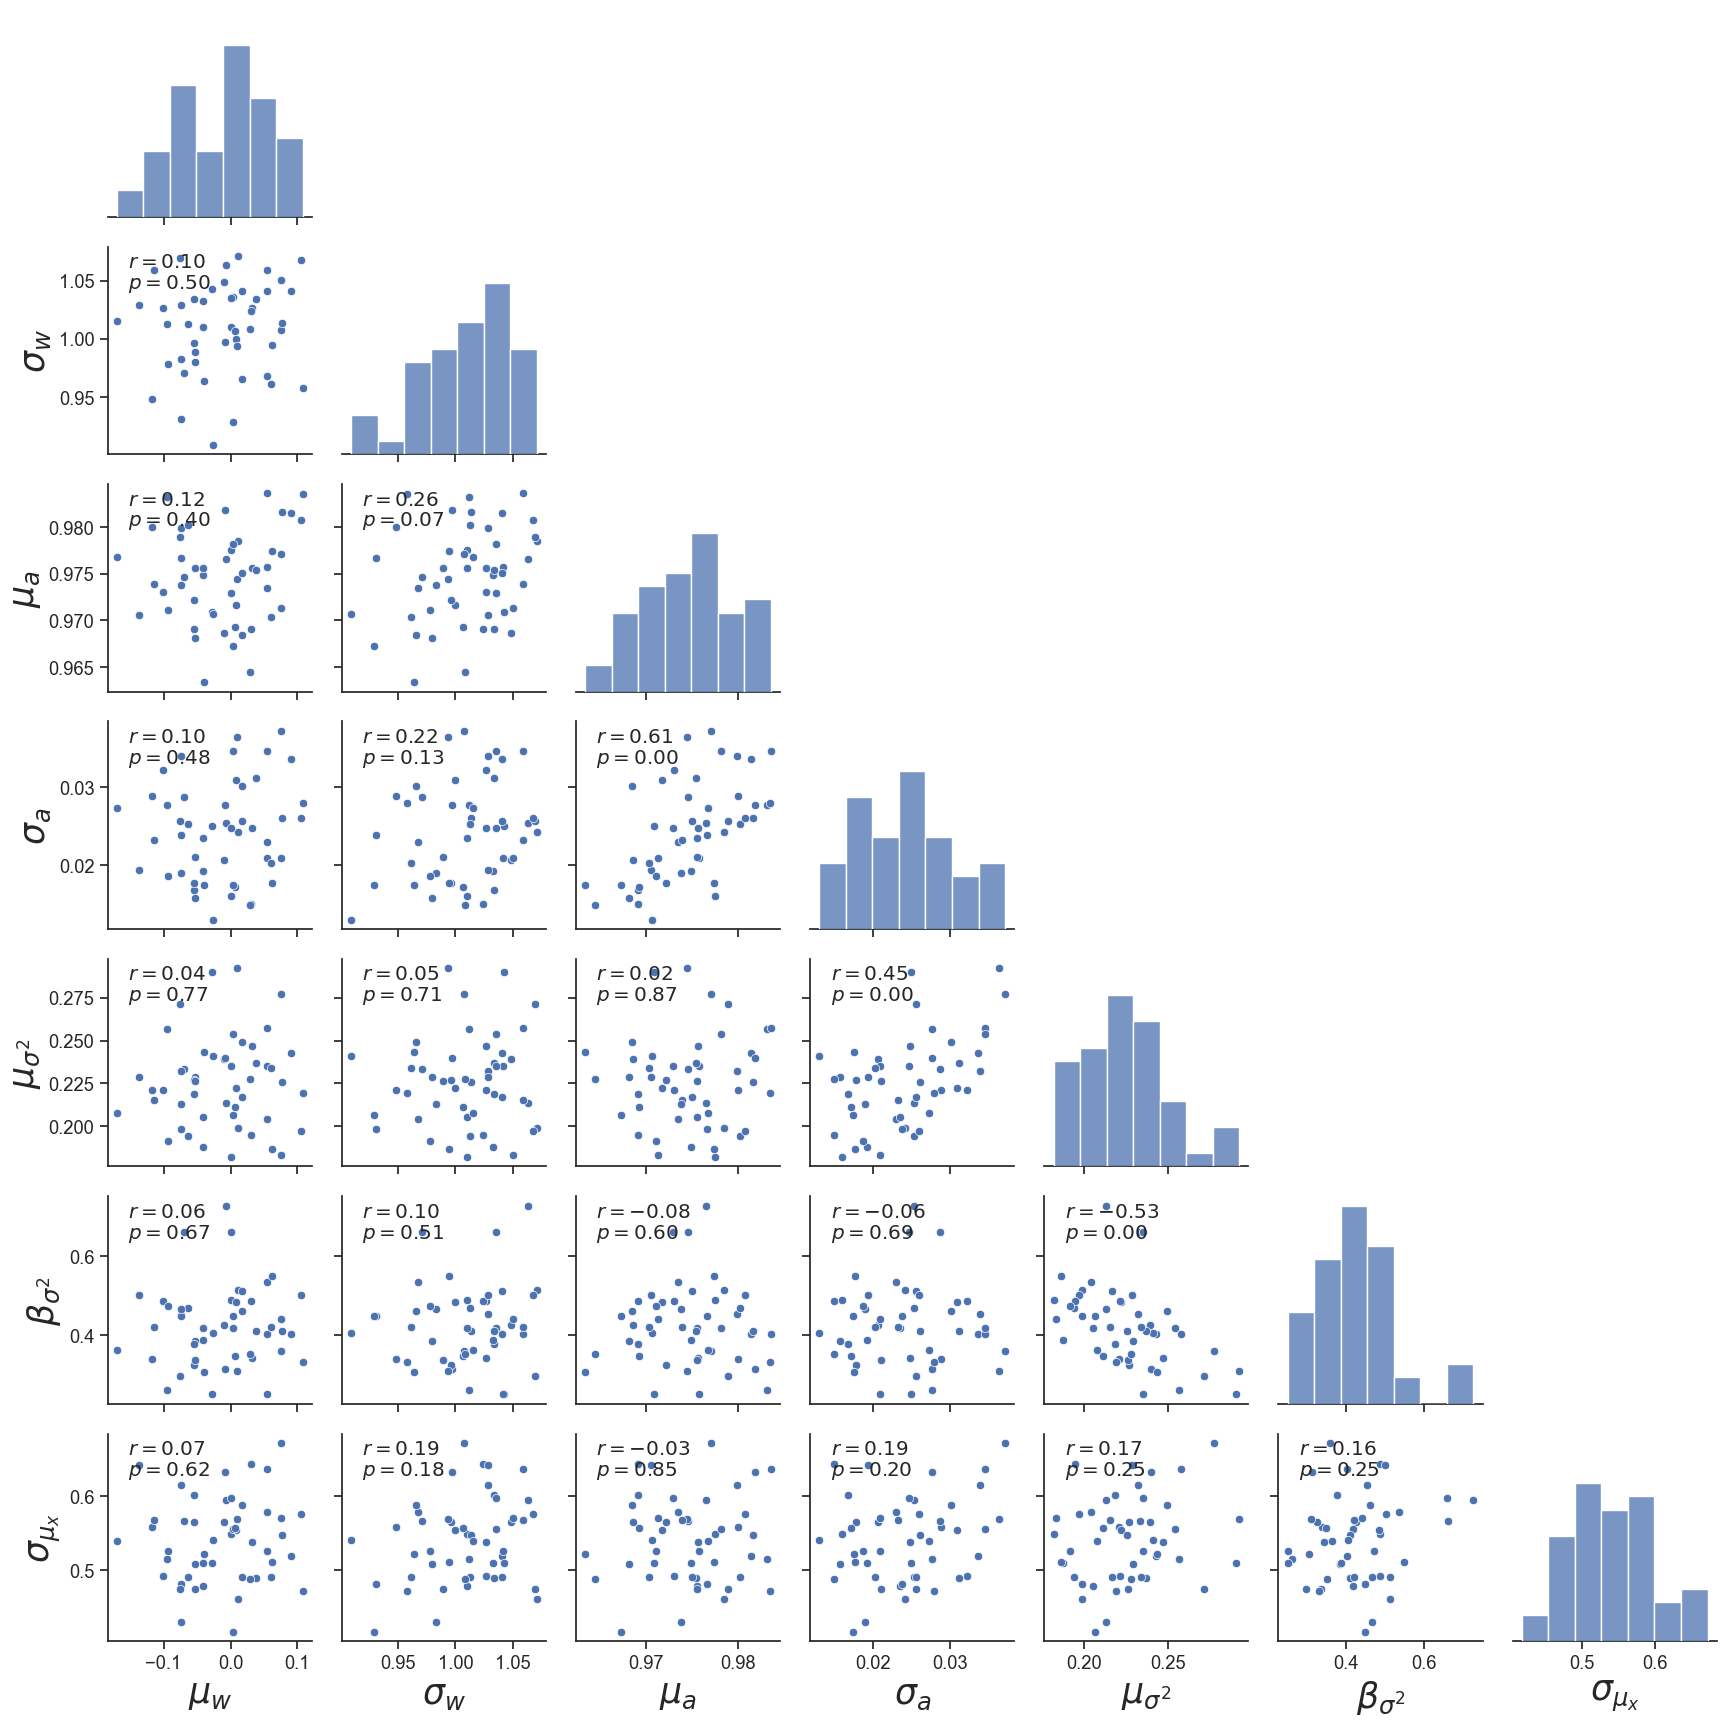

In [37]:
# We don't look at true parameters values here but they are the same over all datasets
all_inf_sigma_mu_x = jnp.stack([jnp.mean(all_posterior_samples_sigma_mu_x[dataset][burn_in:], axis=0) for dataset in range(num_datasets)])
all_inf_mu_sigmasq = jnp.stack([jnp.mean(all_posterior_samples_mu_sigmasq[dataset][burn_in:], axis=0) for dataset in range(num_datasets)])
all_inf_beta_sigmasq = jnp.stack([jnp.mean(all_posterior_samples_beta_sigmasq[dataset][burn_in:], axis=0) for dataset in range(num_datasets)])
all_inf_mu_a = jnp.stack([jnp.mean(all_posterior_samples_mu_a[dataset][burn_in:], axis=0) for dataset in range(num_datasets)])
all_inf_sigma_a = jnp.stack([jnp.mean(all_posterior_samples_sigma_a[dataset][burn_in:], axis=0) for dataset in range(num_datasets)])
all_inf_mu_w = jnp.stack([jnp.mean(all_posterior_samples_mu_w[dataset][burn_in:], axis=0)[0] for dataset in range(num_datasets)])
all_inf_sigma_w = jnp.stack([jnp.mean(all_posterior_samples_sigma_w[dataset][burn_in:], axis=0)[0] for dataset in range(num_datasets)])


df_group_params = pd.DataFrame({
    r"$\mu_w$": all_inf_mu_w,
    r"$\sigma_w$": all_inf_sigma_w,
    r"$\mu_a$": all_inf_mu_a,
    r"$\sigma_a$": all_inf_sigma_a,
    r"$\mu_{\sigma^2}$": all_inf_mu_sigmasq,
    r"$\beta_{\sigma^2}$": all_inf_beta_sigmasq,
    r"$\sigma_{\mu_x}$": all_inf_sigma_mu_x
})

# Define correlation annotation function
def corrfunc(x, y, ax=None, **kws):
    r, p = spearmanr(x, y)
    ax = ax or plt.gca()
    ax.annotate(f'$r = {r:.2f}$', xy=(.1, .9), xycoords=ax.transAxes)
    ax.annotate(f'$p = {p:.2f}$', xy=(.1, .8), xycoords=ax.transAxes)

# Plot with seaborn
sns.set(style="ticks", font_scale=1.2)
g = sns.pairplot(df_group_params, corner=True)
g.map_lower(corrfunc)
for ax in g.axes.flat:
    if ax is not None:
        ax.xaxis.label.set_size(25)  # x-axis label font size
        ax.yaxis.label.set_size(25)  # y-axis label font size
plt.tight_layout()
#plt.savefig("correlation_between_inferred_group_parameters.png", transparent=True, dpi=600)

In [38]:
dataset = 0

df_subject_params = pd.DataFrame({"true mu_x": all_true_params[dataset]['mu_x'],
                                  "true sigmasq": all_true_params[dataset]['sigmasq'],
                                  "true a": all_true_params[dataset]['a'],
                                  "true w": all_true_params[dataset]['w'][:,0], ## problem here?
                                  "inferred mu_x": jnp.mean(all_posterior_samples_mu_x[dataset][burn_in:], axis=0),
                                  "inferred sigmasq": jnp.mean(all_posterior_samples_sigmasq[dataset][burn_in:], axis=0),
                                  "inferred a": jnp.mean(all_posterior_samples_a[dataset][burn_in:], axis=0),
                                  "inferred w": jnp.mean(all_posterior_samples_w[dataset][burn_in:], axis=0)[:,0] # or here?
                                  })

#### Inferred and inferred

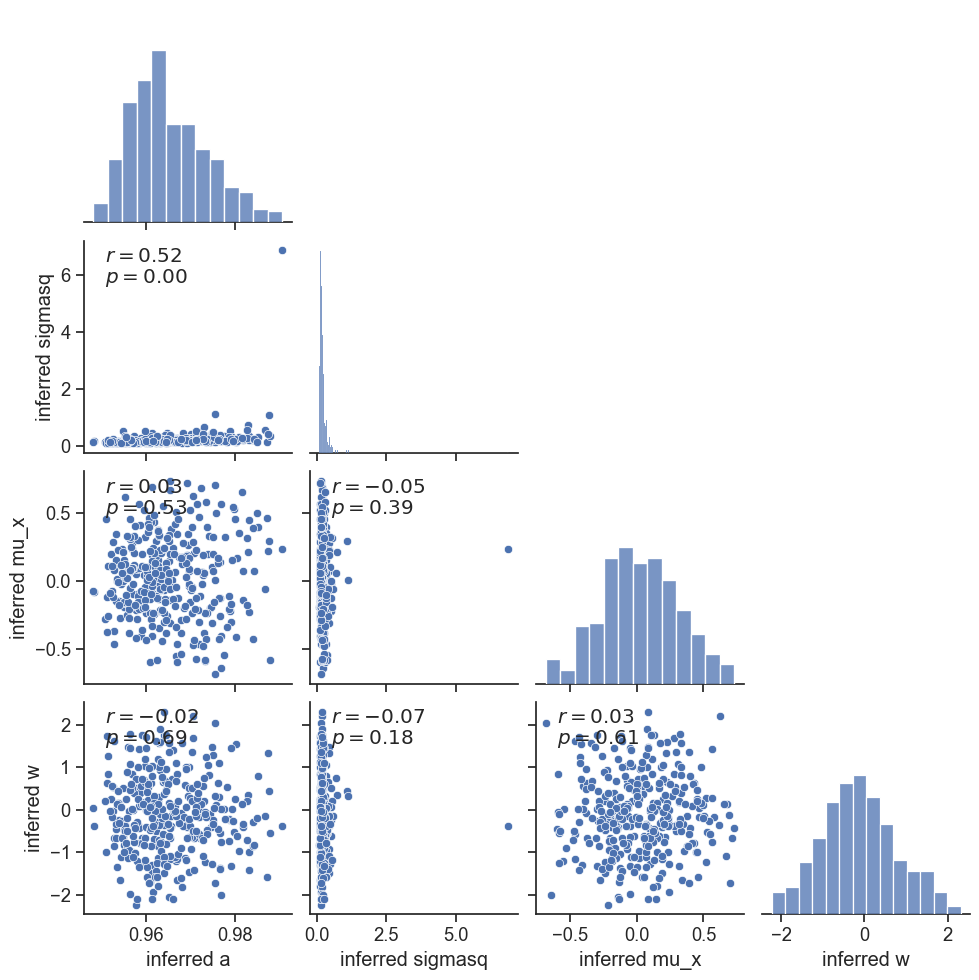

In [39]:
g = sns.pairplot(df_subject_params, 
                 x_vars=("inferred a", "inferred sigmasq", "inferred mu_x", "inferred w"), 
                 y_vars=("inferred a", "inferred sigmasq", "inferred mu_x", "inferred w"), 
                 corner=True)
g.map_lower(corrfunc)
plt.show()

#### True and true

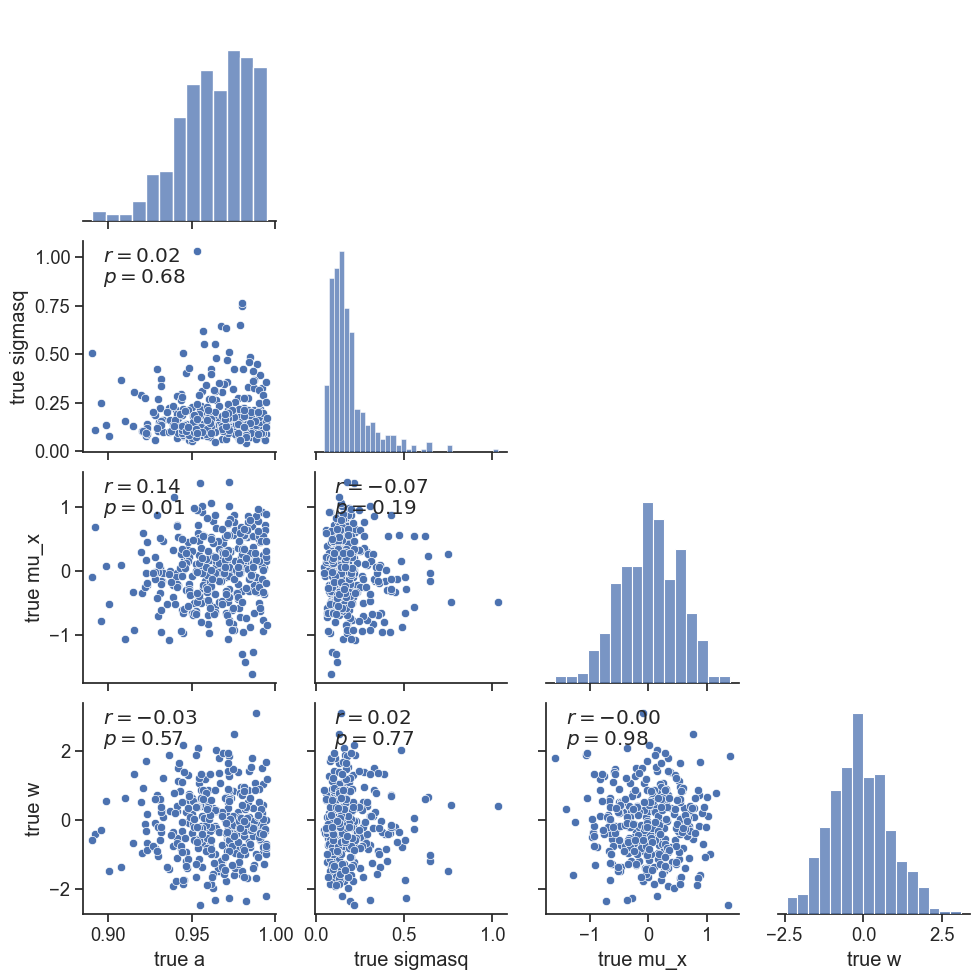

In [40]:
g = sns.pairplot(df_subject_params, 
                 x_vars=("true a", "true sigmasq", "true mu_x", "true w"), 
                 y_vars=("true a","true sigmasq","true mu_x","true w"), 
                 corner=True)
g.map_lower(corrfunc)
plt.show()

#### True and inferred

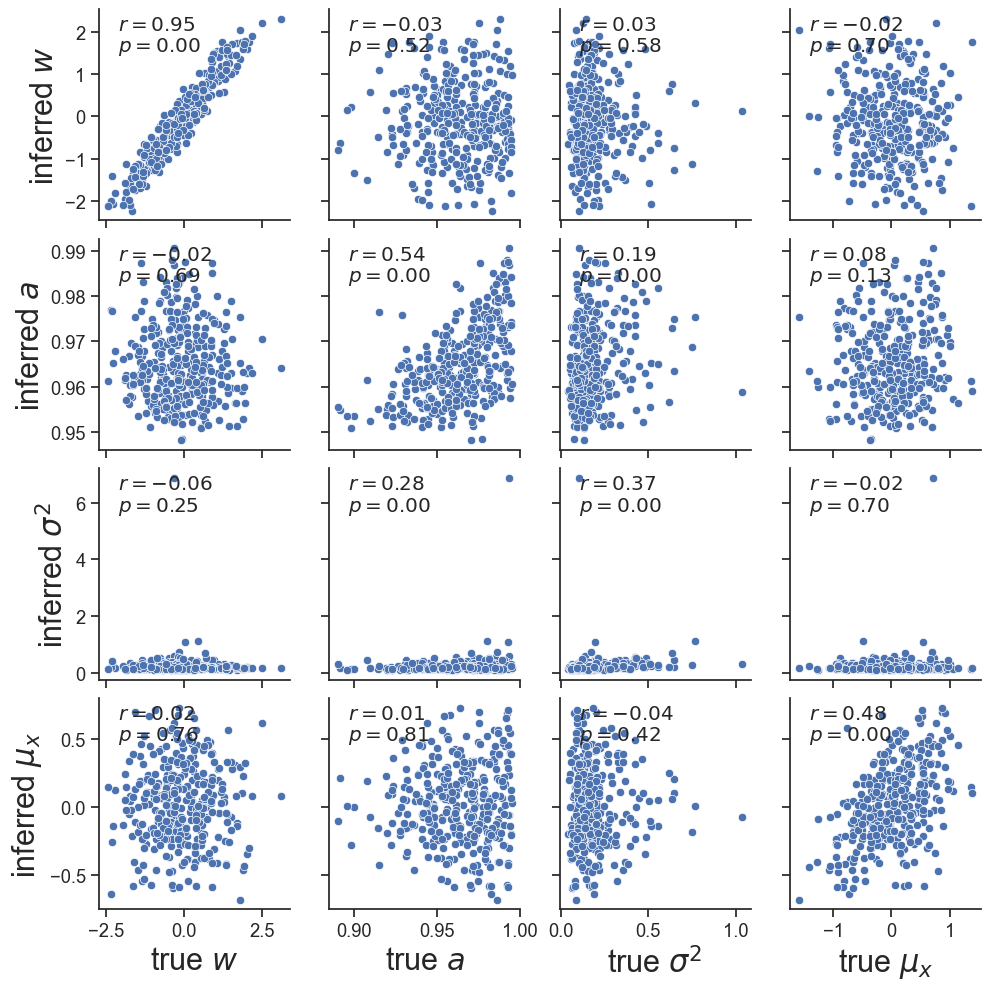

In [41]:
label_map = {
    "true w": r"true $w$",
    "true a": r"true $a$",
    "true sigmasq": r"true $\sigma^2$",
    "true mu_x": r"true $\mu_x$",
    "inferred w": r"inferred $w$",
    "inferred a": r"inferred $a$",
    "inferred sigmasq": r"inferred $\sigma^2$",
    "inferred mu_x": r"inferred $\mu_x$"
    
}

df_labeled = df_subject_params.rename(columns=label_map)

x_vars = [label_map["true w"], label_map["true a"], label_map["true sigmasq"], label_map["true mu_x"]]
y_vars = [label_map["inferred w"], label_map["inferred a"], label_map["inferred sigmasq"], label_map["inferred mu_x"]]

g = sns.pairplot(
    df_labeled,
    x_vars=x_vars,
    y_vars=y_vars,
    corner=False,
    kind="scatter"
)

g.map_lower(corrfunc)
g.map_upper(corrfunc)

for i, (x_var, y_var) in enumerate(zip(x_vars, y_vars)):
    ax = g.axes[i][i]
    x = df_labeled[x_var]
    y = df_labeled[y_var]
    corrfunc(x, y, ax=ax)

for ax_row in g.axes:
    for ax in ax_row:
        if ax is not None:
            ax.xaxis.label.set_size(22)
            ax.yaxis.label.set_size(22)
#plt.savefig("correlation_inferred_true_subject_parameters.png", transparent=True, dpi=600)

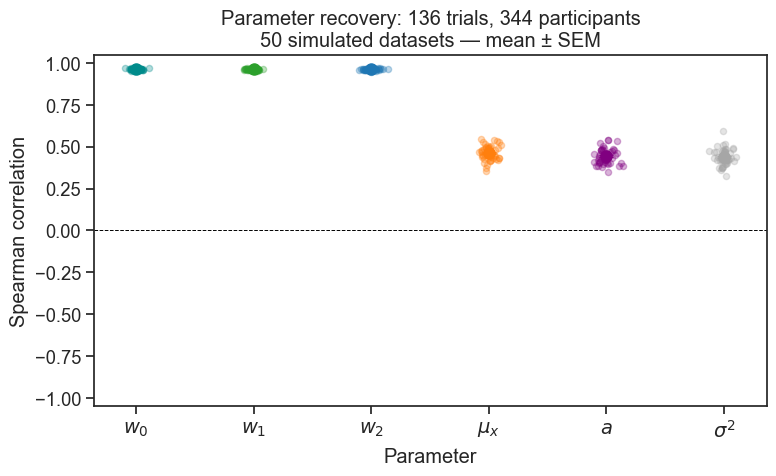

In [43]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path(
    "/Users/daviddejonghe/Documents/Psychologie/Masterproef/"
    "simulationsHmfc/demo/Study1_Benwell/Param_recovery"
)

data = pd.read_csv(
    data_dir / "136trials_344subjects_recovery_localparams.csv"
)

columns = [
    "correlation_w0",
    "correlation_w1",
    "correlation_w2",
    "correlation_mu_x",
    "correlation_a",
    "correlation_sigmasq",
]
labels = [r"$w_0$", r"$w_1$", r"$w_2$",
          r"$\mu_x$", r"$a$", r"$\sigma^2$"]
colors = [
    "darkcyan", "#2ca02c", "#1f77b4",
    "#ff7f0e", "purple", "#A6A6A6"
]

rng = np.random.default_rng(42)
fig, ax = plt.subplots(figsize=(8, 5))

for i, (column, color) in enumerate(zip(columns, colors)):
    values = data[column].dropna().to_numpy()
    if len(values) == 0:
        continue

    mean = values.mean()
    sem = (
        values.std(ddof=1) / np.sqrt(len(values))
        if len(values) > 1 else 0
    )

    ax.scatter(
        i + rng.normal(0, 0.05, len(values)),
        values,
        color=color, alpha=0.3, s=20
    )
    ax.errorbar(
        i, mean, yerr=sem,
        fmt="o", color=color,
        markersize=8, capsize=5, linewidth=2
    )

ax.axhline(0, color="black", linestyle="--", linewidth=0.7)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=14)
ax.set_xlabel("Parameter")
ax.set_ylabel("Spearman correlation")
ax.set_ylim(-1.05, 1.05)
ax.set_title(
    f"Parameter recovery: 136 trials, 344 participants\n"
    f"{len(data)} simulated datasets — mean ± SEM"
)

fig.tight_layout()

plot_dir = data_dir / "figuren_136trials"
plot_dir.mkdir(exist_ok=True)

fig.savefig(
    plot_dir / "recovery_local_parameters.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

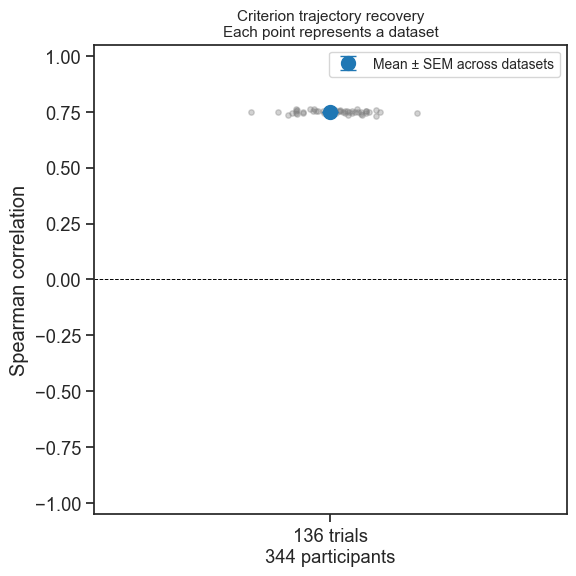

Mean trajectory recovery: 0.749
SEM across datasets: 0.001
Number of valid dataset means: 50


In [45]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path(
    "/Users/daviddejonghe/Documents/Psychologie/Masterproef/"
    "simulationsHmfc/demo/Study1_Benwell/Param_recovery"
)

data_datasets = pd.read_csv(
    data_dir / "136trials_344subjects_recovery_localparams.csv"
)
data_subjects = pd.read_csv(
    data_dir / "136trials_344subjects_recovery_criterion_heatmap.csv"
)

# True: één punt per dataset; False: één punt per deelnemer per dataset.
plot_with_each_dataset_as_point = True
rng = np.random.default_rng(42)

# Gemiddelde en SEM worden altijd over de datasets berekend.
dataset_means = data_datasets["mean_correlation_states"].dropna()
mean_recovery = dataset_means.mean()
sem_recovery = (
    dataset_means.std(ddof=1) / np.sqrt(len(dataset_means))
    if len(dataset_means) > 1 else 0
)

if plot_with_each_dataset_as_point:
    points = dataset_means.to_numpy()
    point_label = "Each point represents a dataset"
    alpha = 0.35
else:
    points = data_subjects["correlation"].dropna().to_numpy()
    point_label = "Each point represents a participant within a dataset"
    alpha = 0.05

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    1 + rng.normal(0, 0.06, len(points)),
    points,
    color="gray", alpha=alpha, s=15
)

ax.errorbar(
    1, mean_recovery, yerr=sem_recovery,
    fmt="o", color="#1f77b4",
    markersize=10, capsize=6, linewidth=2,
    label="Mean ± SEM across datasets"
)

ax.axhline(0, color="black", linestyle="--", linewidth=0.7)
ax.set_xlim(0.65, 1.35)
ax.set_ylim(-1.05, 1.05)
ax.set_xticks([1])
ax.set_xticklabels(["136 trials\n344 participants"])
ax.set_ylabel("Spearman correlation")
ax.set_title(f"Criterion trajectory recovery\n{point_label}", fontsize=11)
ax.legend(fontsize=10)

fig.tight_layout()

plot_dir = data_dir / "figuren_136trials"
plot_dir.mkdir(exist_ok=True)

fig.savefig(
    plot_dir / "correlation_recovery_criterion.png",
    transparent=True, dpi=300, bbox_inches="tight"
)
plt.show()

print(f"Mean trajectory recovery: {mean_recovery:.3f}")
print(f"SEM across datasets: {sem_recovery:.3f}")
print(f"Number of valid dataset means: {len(dataset_means)}")

In [48]:
from pathlib import Path
import pandas as pd

data_dir = Path(
    "/Users/daviddejonghe/Documents/Psychologie/Masterproef/"
    "simulationsHmfc/demo/Study1_Benwell/Param_recovery"
)

# Recovery van het criteriumtraject per deelnemer per dataset.
data = pd.read_csv(
    data_dir / "136trials_344subjects_recovery_criterion_heatmap.csv"
)

print(f"number of rows: {len(data)}")
display(data.head())

number of rows: 17200


,correlation,rmse,generative_a,estimated_a,generative_sigmasq,estimated_sigmasq,generative_mu_x,estimated_mu_x
0,0.760904,0.527915,0.961130,0.961855,0.070853,0.136169,0.177372,0.429598
1,0.794299,0.817632,0.931158,0.957798,0.102122,0.208432,0.040762,0.050939
2,0.934722,0.918806,0.959952,0.967769,0.131415,0.180887,-0.691044,-0.383288
3,0.757784,0.500042,0.956198,0.962110,0.080413,0.099453,0.924262,0.294015
4,0.892061,0.948229,0.975153,0.975418,0.200432,0.143600,0.875705,0.699577


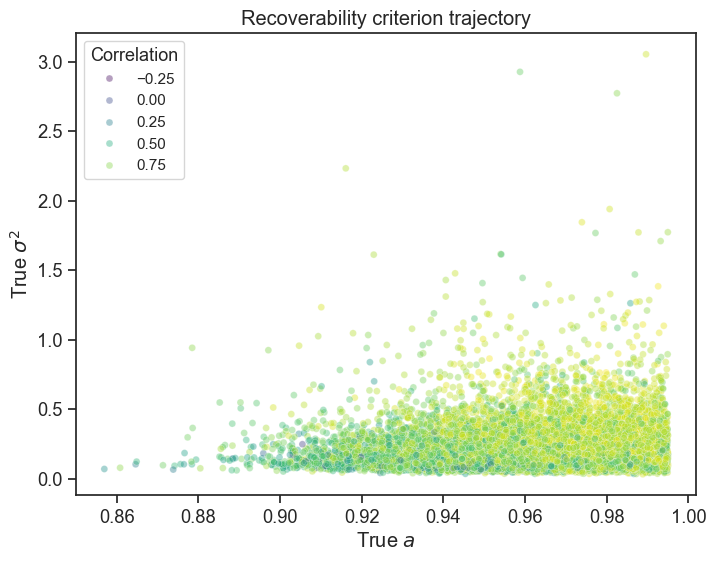

In [49]:
# Plot with generative parameter values
plt.figure(figsize=(8, 6))
sns.scatterplot(x = data["generative_a"], y = data["generative_sigmasq"], hue=data['correlation'], palette='viridis', s=25, alpha=.4)
plt.title('Recoverability criterion trajectory')
plt.xlabel('True $a$')
plt.ylabel(r'True $\sigma^2$')
plt.legend(title='Correlation', title_fontsize='13', fontsize='11')
plt.savefig("criterion_recovery_heatmap.png", transparent=True, dpi=600)

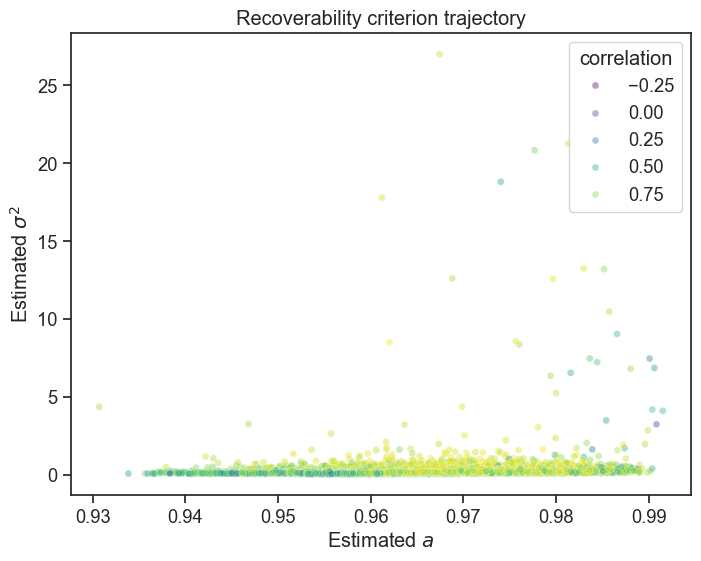

In [50]:
# Plot with estimated parameter values
plt.figure(figsize=(8, 6))
sns.scatterplot(x = data["estimated_a"], y = data["estimated_sigmasq"], hue=data['correlation'], palette='viridis', s=25, alpha=.4)
plt.title('Recoverability criterion trajectory')
plt.xlabel('Estimated $a$')
plt.ylabel('Estimated $\sigma^2$')
plt.show()

In [52]:
"""
Prepare posterior samples for group-level parameters.
Condition: 344 participants and 136 trials per participant.
"""

import numpy as np

# Restore the settings changed by the previous cell.
num_trials = 136
num_subjects = 344

# Use the data previously loaded from 344subjects_136trials.dil.
# Remove burn-in separately for each simulated dataset.
posterior_samples_mu_sigmasq_344 = np.stack(
    all_posterior_samples_mu_sigmasq
)[:, burn_in:]

posterior_samples_beta_sigmasq_344 = np.stack(
    all_posterior_samples_beta_sigmasq
)[:, burn_in:]

posterior_samples_mu_a_344 = np.stack(
    all_posterior_samples_mu_a
)[:, burn_in:]

posterior_samples_sigma_a_344 = np.stack(
    all_posterior_samples_sigma_a
)[:, burn_in:]

posterior_samples_sigma_mu_x_344 = np.stack(
    all_posterior_samples_sigma_mu_x
)[:, burn_in:]

posterior_samples_mu_w_344 = np.stack(
    all_posterior_samples_mu_w
)[:, burn_in:, :]

posterior_samples_sigma_w_344 = np.stack(
    all_posterior_samples_sigma_w
)[:, burn_in:, :]

print("Group-level parameter samples:", posterior_samples_mu_a_344.shape)
print("Weight samples:", posterior_samples_mu_w_344.shape)

Group-level parameter samples: (50, 1000)
Weight samples: (50, 1000, 3)


In [54]:
"""
Prepare posterior summaries and samples for plotting.
Condition: 344 participants, 136 trials per participant.
"""

from pathlib import Path
import numpy as np
import pandas as pd

num_subjects = 344
num_trials = 136

data_dir = Path(
    "/Users/daviddejonghe/Documents/Psychologie/Masterproef/"
    "simulationsHmfc/demo/Study1_Benwell/Param_recovery"
)

# Posterior means and 95% credible intervals for each dataset.
# Burn-in iterations were already excluded during calculation.
df_posterior_mean_subj = pd.read_csv(
    data_dir / "136trials_344subjects_posterior_means.csv"
)

# Determine dimensions from the loaded posterior samples.
n_datasets, n_draws = posterior_samples_mu_a_344.shape

assert len(df_posterior_mean_subj) == n_datasets, (
    "The CSV and posterior samples contain different numbers of datasets."
)

df_posterior_mean_subj["dataset"] = np.arange(n_datasets)
df_posterior_mean_subj["num_subjects"] = num_subjects
df_posterior_mean_subj["num_trials"] = num_trials

# Retain the names used by subsequent plotting cells.
all_posterior_means = df_posterior_mean_subj.copy()
all_posterior_means_subj = df_posterior_mean_subj.copy()

# Match Robin's original plots: display the first weight component.
weight_index = 0

# Each row represents one posterior draw from one dataset.
df_example_post = pd.DataFrame({
    "mu_a": posterior_samples_mu_a_344.reshape(-1),
    "sigma_a": posterior_samples_sigma_a_344.reshape(-1),
    "mu_sigmasq": posterior_samples_mu_sigmasq_344.reshape(-1),
    "beta_sigmasq": posterior_samples_beta_sigmasq_344.reshape(-1),
    "sigma_mu_x": posterior_samples_sigma_mu_x_344.reshape(-1),
    "mu_w": posterior_samples_mu_w_344[
        :, :, weight_index
    ].reshape(-1),
    "sigma_w": posterior_samples_sigma_w_344[
        :, :, weight_index
    ].reshape(-1),
    "num_subjects": num_subjects,
    "num_trials": num_trials,
    "dataset": np.repeat(np.arange(n_datasets), n_draws),
    "draw": np.tile(np.arange(n_draws), n_datasets),
})

df_example_post["num_subjects"] = pd.Categorical(
    df_example_post["num_subjects"],
    categories=[344]
)

print(f"Posterior summary rows: {len(df_posterior_mean_subj)}")
print(f"Posterior sample rows: {len(df_example_post)}")
print(f"Datasets: {n_datasets}; retained draws per dataset: {n_draws}")

display(df_example_post.head())

Posterior summary rows: 50
Posterior sample rows: 50000
Datasets: 50; retained draws per dataset: 1000


,mu_a,sigma_a,mu_sigmasq,beta_sigmasq,sigma_mu_x,mu_w,sigma_w,num_subjects,num_trials,dataset,draw
0,0.974934,0.024833,0.217767,0.366732,0.550474,-0.060427,0.946205,344,136,0,0
1,0.975783,0.027469,0.197451,0.365442,0.589572,-0.162647,0.982017,344,136,0,1
2,0.977151,0.030813,0.187556,0.381629,0.596450,-0.157645,0.915813,344,136,0,2
3,0.982369,0.032747,0.198516,0.346942,0.630561,-0.056839,1.008248,344,136,0,3
4,0.975508,0.031666,0.201129,0.341604,0.621610,-0.183536,0.915452,344,136,0,4


In [ ]:
# Posterior plots for the available condition only.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plot_dir = Path("/Users/daviddejonghe/Documents/Psychologie/Masterproef/simulationsHmfc/demo/Study1_Benwell/Param_recovery/figuren_136trials")
plot_dir.mkdir(exist_ok=True)

def plot_single_condition_posterior(samples, true_value, symbol, example_dataset, filename):
    samples = np.asarray(samples)
    true_value = float(true_value)
    assert samples.ndim == 2, "Expected datasets by posterior draws."
    assert np.isfinite(samples).all(), "Non-finite posterior draws found."
    assert 0 <= example_dataset < len(samples)
    fig, axes = plt.subplots(2, 1, figsize=(7, 8))
    sns.kdeplot(x=samples[example_dataset], bw_adjust=2, cut=0,
                fill=True, color="#3b528b", alpha=0.5, ax=axes[0])
    axes[0].axvline(true_value, color="red", linestyle="--",
                   label=f"Generating parameter: {true_value:g}")
    axes[0].set(title=f"Example posterior — dataset index {example_dataset}\n344 participants, 136 trials",
                xlabel=f"${symbol}$", ylabel="Density")
    axes[0].legend(fontsize=10)
    for draws in samples:
        sns.kdeplot(x=draws - true_value, bw_adjust=2, cut=0,
                    color="#3b528b", alpha=0.2, linewidth=1, ax=axes[1])
    axes[1].axvline(0, color="red", linestyle="--")
    axes[1].set(title=f"Truth-centred posteriors — {len(samples)} datasets",
                xlabel=f"${symbol} - ({symbol})^{{*}}$", ylabel="Density")
    fig.tight_layout()
    fig.savefig(plot_dir / filename, transparent=True, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [ ]:
# Posterior for mu_a; each curve represents one simulated dataset.
# The reference is the generating hyperparameter, not a sample statistic.
plot_single_condition_posterior(
    posterior_samples_mu_a_344,
    true_mu_a, r"\mu_a", 19,
    "corrected_posteriors_mu_a.png"
)


In [ ]:
# Posterior for sigma_a; each curve represents one simulated dataset.
# The reference is the generating hyperparameter, not a sample statistic.
plot_single_condition_posterior(
    posterior_samples_sigma_a_344,
    true_sigma_a, r"\sigma_a", 10,
    "corrected_posteriors_sigma_a.png"
)


In [ ]:
# Posterior for mu_sigmasq; each curve represents one simulated dataset.
# The reference is the generating hyperparameter, not a sample statistic.
plot_single_condition_posterior(
    posterior_samples_mu_sigmasq_344,
    true_mu_sigmasq, r"\mu_{\sigma^2}", 12,
    "corrected_posteriors_mu_sigmasq.png"
)


In [ ]:
# Posterior for beta_sigmasq; each curve represents one simulated dataset.
# The reference is the generating hyperparameter, not a sample statistic.
plot_single_condition_posterior(
    posterior_samples_beta_sigmasq_344,
    true_beta_sigmasq, r"\beta_{\sigma^2}", 12,
    "corrected_posteriors_beta_sigmasq.png"
)


In [ ]:
# Posterior for sigma_mu_x; each curve represents one simulated dataset.
# The reference is the generating hyperparameter, not a sample statistic.
plot_single_condition_posterior(
    posterior_samples_sigma_mu_x_344,
    true_sigma_mu_x, r"\sigma_{\mu_x}", 12,
    "corrected_posteriors_sigma_mu_x.png"
)


In [ ]:
# Posterior for mu_w; each curve represents one simulated dataset.
# The reference is the generating hyperparameter, not a sample statistic.
plot_single_condition_posterior(
    posterior_samples_mu_w_344[:, :, 0],
    true_mu_w[0], r"\mu_{w_0}", 19,
    "corrected_posteriors_mu_w.png"
)


In [ ]:
# Posterior for sigma_w; each curve represents one simulated dataset.
# The reference is the generating hyperparameter, not a sample statistic.
plot_single_condition_posterior(
    posterior_samples_sigma_w_344[:, :, 0],
    true_sigma_w[0], r"\sigma_{w_0}", 27,
    "corrected_posteriors_sigma_w.png"
)


### Trial-count comparisons: not available

Only the 344-participant, 136-trial condition has been supplied. The original comparison code is preserved in this cell’s metadata and in the backup notebook. No comparison with 500, 1,000, 2,500 or 5,000 trials is calculated.


Original trial-comparison cell retained in metadata; not executed because the required conditions are unavailable.


Original trial-comparison cell retained in metadata; not executed because the required conditions are unavailable.


Original trial-comparison cell retained in metadata; not executed because the required conditions are unavailable.


Original trial-comparison cell retained in metadata; not executed because the required conditions are unavailable.


Original trial-comparison cell retained in metadata; not executed because the required conditions are unavailable.


Original trial-comparison cell retained in metadata; not executed because the required conditions are unavailable.


Original trial-comparison cell retained in metadata; not executed because the required conditions are unavailable.


Original trial-comparison cell retained in metadata; not executed because the required conditions are unavailable.
